# Đề kiểm tra thực hành 2.2 - Solutions

**Phân tích dữ liệu Bayesian - IUH**

**Ngày: 29/04/2026**

**Lớp: DHKHDL18A (Nhóm TH3)**

Bài kiểm tra này là phiên bản cải tiến của Thuchanh2, với các dạng bài khác biệt:
- **Câu 1**: Beta-Binomial conjugacy (thay vì Normal-Normal)
- **Câu 2**: Gamma-Poisson conjugacy (thay vì custom prior/likelihood)
- **Câu 3**: Mixture prior với 3 components
- **Câu 4**: Bayesian regression - lương theo kinh nghiệm

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pymc as pm
import arviz as az

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
np.random.seed(42)

## Câu 1: Beta-Binomial Conjugacy và MAP (2 điểm)

### Đề bài

Một công ty đang thử nghiệm một chiến dịch quảng cáo mới. Dựa trên kinh nghiệm trước đây, họ tin rằng tỷ lệ chuyển đổi $\theta$ có phân phối tiên nghiệm Beta với tham số $\alpha_0 = 5$ và $\beta_0 = 15$ (tức là $\theta \sim \text{Beta}(5, 15)$).

Sau khi chạy chiến dịch trên 100 người dùng, có 12 người chuyển đổi thành công.

Hãy tính ước lượng MAP (Maximum A Posteriori) cho tỷ lệ chuyển đổi $\theta$.

### Lý thuyết

**Beta-Binomial conjugacy** là một trong những cặp liên hợp cơ bản nhất:

- **Prior**: $\theta \sim \text{Beta}(\alpha_0, \beta_0)$
- **Likelihood**: $k \sim \text{Binomial}(n, \theta)$ (k successes trong n trials)
- **Posterior**: $\theta|k \sim \text{Beta}(\alpha_0 + k, \beta_0 + n - k)$

**Cập nhật Bayesian:**

Với prior Beta và likelihood Binomial, posterior cũng là Beta:

$$
\theta | D \sim \text{Beta}(\alpha_0 + x, \beta_0 + n - x)
$$

Trong bài này:

$$
\begin{aligned}
\theta | D &\sim \text{Beta}(5 + 12, 15 + 88) \\\\
\theta | D &\sim \text{Beta}(17, 103)
\end{aligned}
$$

Với $\text{Beta}(\alpha, \beta)$:
- **Mean**: $E[\theta] = \frac{\alpha}{\alpha + \beta}$
- **Mode (MAP)**: $\text{Mode}[\theta] = \frac{\alpha - 1}{\alpha + \beta - 2}$ (khi $\alpha, \beta > 1$)

#### **MAP (Maximum A Posteriori) - Giải thích chi tiết:**

**MAP** là **giá trị của tham số $\theta$ làm cho mật độ xác suất posterior $P(\theta \mid D)$ đạt cực đại**:

$$
\hat{\theta}_{MAP} = \arg\max_{\theta} P(\theta \mid D) = \arg\max_{\theta} \left[ P(D \mid \theta) \cdot P(\theta) \right]
$$

- MAP là **đỉnh** (mode) của phân phối posterior
- Là giá trị có **xác suất mật độ cao nhất**
- Tối ưu cho **hàm tổn thất 0-1**

**Lưu ý:** Với phân phối Beta lệch phải ($\alpha < \beta$), MAP thường khác Mean vì:

$$
\text{Mode} < \text{Median} < \text{Mean}
$$

Đuôi dài bên phải của Beta kéo Mean cao hơn Mode.

In [18]:
# Dữ liệu
alpha0 = 5    # Prior alpha
beta0 = 15    # Prior beta
n = 100       # Số người dùng
k = 12        # Số người chuyển đổi

# Posterior parameters
alpha_post = alpha0 + k
beta_post = beta0 + (n - k)

print("="*60)
print("PRIOR và DATA")
print("="*60)
print(f"Prior: Beta({alpha0}, {beta0})")
print(f"Prior mean: {alpha0/(alpha0+beta0):.4f}")
print(f"Prior mode: {(alpha0-1)/(alpha0+beta0-2):.4f}")
print(f"\nData: {k} successes trong {n} trials")
print(f"MLE (frequentist): {k/n:.4f}")

print("\n" + "="*60)
print("POSTERIOR")
print("="*60)
print(f"Posterior: Beta({alpha_post}, {beta_post})")

# Tính MAP
map_estimate = (alpha_post - 1) / (alpha_post + beta_post - 2)

print(f"\n✅ MAP (Maximum A Posteriori) = {map_estimate:.6f}")
print(f"   Công thức: (α-1)/(α+β-2) = ({alpha_post}-1)/({alpha_post}+{beta_post}-2)")
print(f"   MAP = {alpha_post-1}/{alpha_post+beta_post-2} = {map_estimate:.6f}")

print(f"\n💡 Giải thích:")
print(f"   • Prior tin tỷ lệ conversion ~{alpha0/(alpha0+beta0):.1%}")
print(f"   • Data thực tế: {k}/{n} = {k/n:.1%}")
print(f"   • Posterior MAP: ~{map_estimate:.1%}")
print(f"   • Posterior cân bằng giữa prior và data")


PRIOR và DATA
Prior: Beta(5, 15)
Prior mean: 0.2500
Prior mode: 0.2222

Data: 12 successes trong 100 trials
MLE (frequentist): 0.1200

POSTERIOR
Posterior: Beta(17, 103)

✅ MAP (Maximum A Posteriori) = 0.135593
   Công thức: (α-1)/(α+β-2) = (17-1)/(17+103-2)
   MAP = 16/118 = 0.135593

💡 Giải thích:
   • Prior tin tỷ lệ conversion ~25.0%
   • Data thực tế: 12/100 = 12.0%
   • Posterior MAP: ~13.6%
   • Posterior cân bằng giữa prior và data


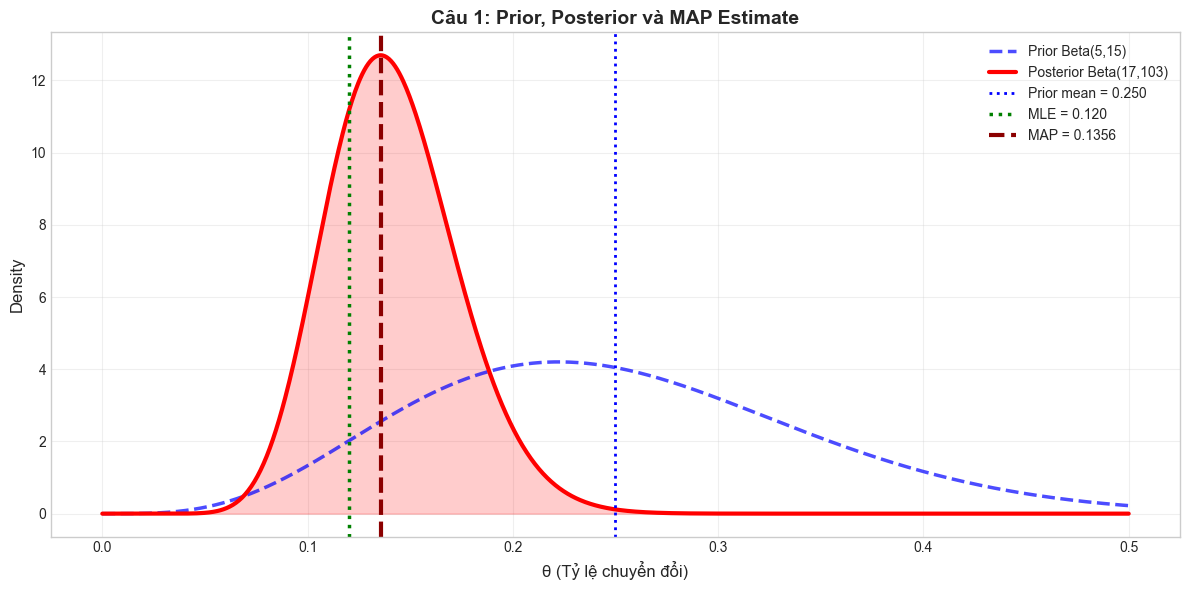


📊 GIẢI THÍCH BIỂU ĐỒ - CÂU 1: BETA-BINOMIAL CONJUGACY

🔵 ĐƯỜNG XANH CHẤM - Prior Beta(5,15):
   • Prior mean = 0.250 (25% conversion rate)
   • Dựa trên kinh nghiệm: tin tỷ lệ ~15-35%
   • Phân phối rộng → prior không chắc chắn lắm

🔴 ĐƯỜNG ĐỎ - Posterior Beta(17,103):
   • Sau khi quan sát: 12/100 chuyển đổi
   • Thu hẹp mạnh, tập trung quanh 13.6%
   • Data kéo xuống thấp hơn prior (12% < 25%)

🟩 ĐƯỜNG XANH LÁ DỌC - MLE:
   • MLE = 0.120 (frequentist estimate)
   • Chỉ dựa vào data, không có prior

🟫 ĐƯỜNG ĐỎ ĐẬM CHẤM - MAP:
   • MAP = 0.1356
   • Công thức: (α-1)/(α+β-2) = 16/118
   • Đỉnh của phân phối (giá trị làm P(θ|D) CỰC ĐẠI)
   • Tối ưu cho hàm tổn thất 0-1

🟥 VÙNG TÔ MÀU ĐỎ:
   • Toàn bộ phân phối posterior
   • Càng cao = xác suất mật độ càng lớn

💡 QUÁ TRÌNH CẬP NHẬT BAYESIAN:
   1. Prior: Tin conversion ~25% (không chắc)
   2. Data: Thực tế 12/100 = 12%
   3. Posterior: MAP = 13.6% (rất chắc)
   4. Data mạnh (n=100) kéo về phía MLE
   5. Nhưng prior vẫn có ảnh hưởng: MAP

In [19]:
# Visualization - Single plot với MAP
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

theta_range = np.linspace(0, 0.5, 1000)

prior_pdf = stats.beta.pdf(theta_range, alpha0, beta0)
posterior_pdf = stats.beta.pdf(theta_range, alpha_post, beta_post)

plt.figure(figsize=(12, 6))

# Prior vs Posterior với MAP
plt.plot(theta_range, prior_pdf, "b--", label=f"Prior Beta({alpha0},{beta0})", linewidth=2.5, alpha=0.7)
plt.plot(theta_range, posterior_pdf, "r-", label=f"Posterior Beta({alpha_post},{beta_post})", linewidth=3)

# Landmarks
plt.axvline(alpha0/(alpha0+beta0), color="b", linestyle=":", linewidth=2, 
            label=f"Prior mean = {alpha0/(alpha0+beta0):.3f}")
plt.axvline(k/n, color="green", linestyle=":", linewidth=2.5,
            label=f"MLE = {k/n:.3f}")
plt.axvline(map_estimate, color="darkred", linestyle="--", linewidth=3, 
            label=f"MAP = {map_estimate:.4f}")

plt.fill_between(theta_range, posterior_pdf, alpha=0.2, color="red")

plt.xlabel("θ (Tỷ lệ chuyển đổi)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.title("Câu 1: Prior, Posterior và MAP Estimate", fontsize=14, fontweight='bold')
plt.legend(loc="upper right", fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# GIẢI THÍCH BIỂU ĐỒ
print('\n' + '='*70)
print('📊 GIẢI THÍCH BIỂU ĐỒ - CÂU 1: BETA-BINOMIAL CONJUGACY')
print('='*70)

print('\n🔵 ĐƯỜNG XANH CHẤM - Prior Beta(5,15):')
print(f'   • Prior mean = {alpha0/(alpha0+beta0):.3f} (25% conversion rate)')
print('   • Dựa trên kinh nghiệm: tin tỷ lệ ~15-35%')
print('   • Phân phối rộng → prior không chắc chắn lắm')

print('\n🔴 ĐƯỜNG ĐỎ - Posterior Beta(17,103):')
print(f'   • Sau khi quan sát: {k}/{n} chuyển đổi')
print(f'   • Thu hẹp mạnh, tập trung quanh {map_estimate:.1%}')
print('   • Data kéo xuống thấp hơn prior (12% < 25%)')

print('\n🟩 ĐƯỜNG XANH LÁ DỌC - MLE:')
print(f'   • MLE = {k/n:.3f} (frequentist estimate)')
print('   • Chỉ dựa vào data, không có prior')

print('\n🟫 ĐƯỜNG ĐỎ ĐẬM CHẤM - MAP:')
print(f'   • MAP = {map_estimate:.4f}')
print(f'   • Công thức: (α-1)/(α+β-2) = {alpha_post-1}/{alpha_post+beta_post-2}')
print('   • Đỉnh của phân phối (giá trị làm P(θ|D) CỰC ĐẠI)')
print('   • Tối ưu cho hàm tổn thất 0-1')

print('\n🟥 VÙNG TÔ MÀU ĐỎ:')
print('   • Toàn bộ phân phối posterior')
print('   • Càng cao = xác suất mật độ càng lớn')

print('\n💡 QUÁ TRÌNH CẬP NHẬT BAYESIAN:')
print(f'   1. Prior: Tin conversion ~25% (không chắc)')
print(f'   2. Data: Thực tế 12/100 = 12%')
print(f'   3. Posterior: MAP = {map_estimate:.1%} (rất chắc)')
print(f'   4. Data mạnh (n=100) kéo về phía MLE')
print(f'   5. Nhưng prior vẫn có ảnh hưởng: MAP({map_estimate:.3f}) nằm giữa')
print(f'      Prior mean({alpha0/(alpha0+beta0):.3f}) và MLE({k/n:.3f})')

print('='*70)


## Câu 2: Gamma-Poisson Conjugacy và Loss Functions (3 điểm)

### Đề bài

Số cuộc gọi đến một tổng đài được mô hình hóa bởi phân phối Poisson với tham số $\lambda$ (số cuộc gọi trung bình mỗi giờ).

Dựa trên dữ liệu lịch sử, ta chọn phân phối tiên nghiệm $\lambda \sim \text{Gamma}(\alpha_0=3, \beta_0=0.5)$ (với mean = $\alpha_0/\beta_0 = 6$ cuộc gọi/giờ).

Trong 5 giờ quan sát, ta ghi nhận được số cuộc gọi lần lượt là: 8, 5, 7, 6, 9 (tổng cộng 35 cuộc gọi trong 5 giờ).

**Lưu ý:** Với prior $\text{Gamma}(\alpha_0, \beta_0)$ và dữ liệu Poisson có tổng $\sum y_i$ trong $n$ quan sát, posterior là $(\text{Gamma}\alpha_0 + \sum y_i, \beta_0 + n)$.

Hãy tính:
- a) Ước lượng posterior mean (tối ưu cho hàm tổn thất bình phương).
- b) Ước lượng posterior mode hay MAP (tối ưu cho hàm tổn thất 0-1).
- c) Vẽ đồ thị phân phối posterior và đánh dấu các ước lượng điểm trên.

### Lý thuyết

**Gamma-Poisson conjugacy**:

- **Prior**: $\lambda \sim \text{Gamma}(\alpha_0, \beta_0)$
- **Likelihood**: $y_i \sim \text{Poisson}(\lambda)$
- **Posterior**: $\lambda|y \sim \text{Gamma}(\alpha_0 + \sum y_i, \beta_0 + n)$

Với $\text{Gamma}(\alpha, \beta)$:
- **Mean**: $E[\lambda] = \frac{\alpha}{\beta}$
- **Mode**: $\text{Mode}[\lambda] = \frac{\alpha - 1}{\beta}$ (khi $\alpha > 1$)

**Loss functions**:
- **Squared loss** $L(\theta, \hat{\theta}) = (\theta - \hat{\theta})^2$ → optimal: **Mean**
- **Absolute loss** $L(\theta, \hat{\theta}) = |\theta - \hat{\theta}|$ → optimal: **Median**
- **0-1 loss** $L(\theta, \hat{\theta}) = \mathbb{1}_{\theta \neq \hat{\theta}}$ → optimal: **Mode (MAP)**

In [20]:
# Dữ liệu
alpha0 = 3
beta0 = 0.5
data = np.array([8, 5, 7, 6, 9])
n = len(data)
sum_y = np.sum(data)

# Posterior parameters
alpha_post = alpha0 + sum_y
beta_post = beta0 + n

print("="*60)
print("PRIOR và DATA")
print("="*60)
print(f"Prior: Gamma({alpha0}, {beta0})")
print(f"Prior mean: {alpha0/beta0:.2f} cuộc gọi/giờ")
print(f"Prior mode: {(alpha0-1)/beta0:.2f} cuộc gọi/giờ")
print(f"\\nData: {data}")
print(f"Tổng: {sum_y} cuộc gọi trong {n} giờ")
print(f"MLE (sample mean): {sum_y/n:.2f} cuộc gọi/giờ")

print("\\n" + "="*60)
print("POSTERIOR")
print("="*60)
print(f"Posterior: Gamma({alpha_post}, {beta_post})")

# a) Mean
post_mean = alpha_post / beta_post
print(f"\\na) Posterior mean (optimal cho squared loss): {post_mean:.4f}")

# b) Mode (MAP)
post_mode = (alpha_post - 1) / beta_post
print(f"b) Posterior mode/MAP (optimal cho 0-1 loss): {post_mode:.4f}")

# Median (bonus)
post_median = stats.gamma.median(alpha_post, scale=1/beta_post)
print(f"\\n   Bonus - Median (optimal cho absolute loss): {post_median:.4f}")

print(f"\\n   Thứ tự: Mode < Median < Mean (Gamma lệch phải)")

PRIOR và DATA
Prior: Gamma(3, 0.5)
Prior mean: 6.00 cuộc gọi/giờ
Prior mode: 4.00 cuộc gọi/giờ
\nData: [8 5 7 6 9]
Tổng: 35 cuộc gọi trong 5 giờ
MLE (sample mean): 7.00 cuộc gọi/giờ
\n============================================================
POSTERIOR
Posterior: Gamma(38, 5.5)
\na) Posterior mean (optimal cho squared loss): 6.9091
b) Posterior mode/MAP (optimal cho 0-1 loss): 6.7273
\n   Bonus - Median (optimal cho absolute loss): 6.8486
\n   Thứ tự: Mode < Median < Mean (Gamma lệch phải)


/var/folders/y9/c3slzxfd321fc72y_8f52hl00000gn/T/ipykernel_80626/1143684733.py:23: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  plt.plot(lambda_range, posterior_pdf, "r-", linewidth=3, label="Posterior", color="crimson")


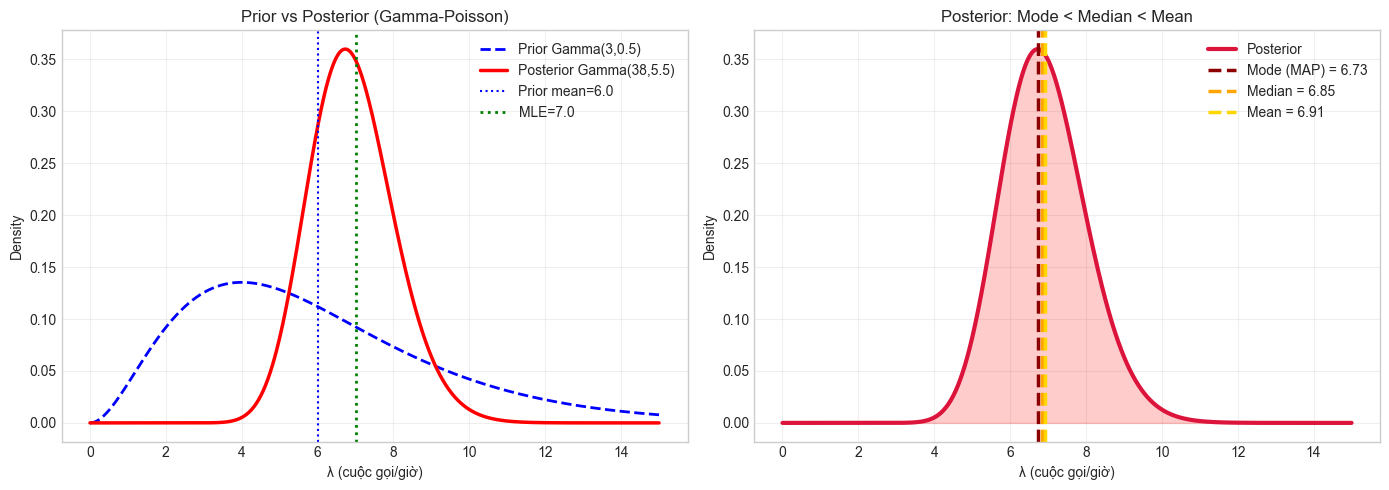

\n📊 Giải thích:
   - Mode là đỉnh của phân phối (xác suất cao nhất)
   - Median là điểm chia đôi phân phối
   - Mean bị kéo sang phải do đuôi dài (Gamma lệch phải)
   - Với 5 quan sát, posterior gần với MLE = 7.00


In [21]:
# c) Visualization
lambda_range = np.linspace(0, 15, 1000)

prior_pdf = stats.gamma.pdf(lambda_range, alpha0, scale=1/beta0)
posterior_pdf = stats.gamma.pdf(lambda_range, alpha_post, scale=1/beta_post)

plt.figure(figsize=(14, 5))

# Prior vs Posterior
plt.subplot(1, 2, 1)
plt.plot(lambda_range, prior_pdf, "b--", label=f"Prior Gamma({alpha0},{beta0})", linewidth=2)
plt.plot(lambda_range, posterior_pdf, "r-", label=f"Posterior Gamma({alpha_post},{beta_post})", linewidth=2.5)
plt.axvline(alpha0/beta0, color="b", linestyle=":", label=f"Prior mean={alpha0/beta0:.1f}")
plt.axvline(sum_y/n, color="green", linestyle=":", linewidth=2, label=f"MLE={sum_y/n:.1f}")
plt.xlabel("λ (cuộc gọi/giờ)")
plt.ylabel("Density")
plt.title("Prior vs Posterior (Gamma-Poisson)")
plt.legend()
plt.grid(True, alpha=0.3)

# Posterior với các estimates
plt.subplot(1, 2, 2)
plt.plot(lambda_range, posterior_pdf, "r-", linewidth=3, label="Posterior", color="crimson")
plt.axvline(post_mode, color="darkred", linestyle="--", linewidth=2.5, label=f"Mode (MAP) = {post_mode:.2f}")
plt.axvline(post_median, color="orange", linestyle="--", linewidth=2.5, label=f"Median = {post_median:.2f}")
plt.axvline(post_mean, color="gold", linestyle="--", linewidth=2.5, label=f"Mean = {post_mean:.2f}")
plt.fill_between(lambda_range, posterior_pdf, alpha=0.2, color="red")
plt.xlabel("λ (cuộc gọi/giờ)")
plt.ylabel("Density")
plt.title("Posterior: Mode < Median < Mean")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\\n📊 Giải thích:")
print(f"   - Mode là đỉnh của phân phối (xác suất cao nhất)")
print(f"   - Median là điểm chia đôi phân phối")
print(f"   - Mean bị kéo sang phải do đuôi dài (Gamma lệch phải)")
print(f"   - Với {n} quan sát, posterior gần với MLE = {sum_y/n:.2f}")

## Câu 3: Phân phối tiên nghiệm hỗn hợp 3 thành phần (3 điểm)

### Đề bài

Cho phân phối tiên nghiệm $\mu$ hỗn hợp gồm:
- $35\%$ phân phối chuẩn $N(10, 1.5^2)$
- $40\%$ phân phối chuẩn $N(12, 2^2)$
- $25\%$ phân phối chuẩn $N(15, 1.8^2)$

a) Xác định phân phối tiên nghiệm của $\mu$, bao gồm cả kỳ vọng lẫn phương sai.

b) Vẽ đồ thị cho phân phối tiên nghiệm và hậu nghiệm trên cùng một hệ trục tọa độ.

### Ý nghĩa của bài tập

**Mixture distribution** (phân phối hỗn hợp) là công cụ mạnh mẽ trong Bayesian modeling để:
1. Mô hình hóa sự không đồng nhất trong prior knowledge
2. Kết hợp ý kiến từ nhiều chuyên gia
3. Mô tả các quần thể có nhiều nhóm con

So với Câu 3 của Thuchanh2 (2 thành phần), bài này có **3 thành phần** với:
- Các mean khác nhau nhiều hơn (10, 12, 15)
- Các variance khác nhau
- Trọng số khác nhau (35%, 40%, 25%)

### Công thức cốt lõi

**Prior hỗn hợp**:
$$
f_\mu(x) = \sum_{k=1}^{3} w_k \cdot \mathcal{N}(x; \mu_k, \sigma_k^2)
$$

với $\sum_{k=1}^3 w_k = 1$.

**Kỳ vọng**:
$$
E[\mu] = \sum_{k=1}^{3} w_k \mu_k
$$

**Phương sai** (công thức tổng quát):
$$
\text{Var}(\mu) = E[\mu^2] - E[\mu]^2
$$

trong đó:
$$
E[\mu^2] = \sum_{k=1}^{3} w_k(\sigma_k^2 + \mu_k^2)
$$

**Posterior hỗn hợp**: Khi có dữ liệu $y_1, \ldots, y_n$ với $y_i \sim N(\mu, \sigma_{obs}^2)$, mỗi component được cập nhật độc lập theo công thức conjugacy, và trọng số được cập nhật theo Bayes factor:

$$
w_k^{\text{post}} \propto w_k^{\text{prior}} \cdot P(\text{data} | \text{component } k)
$$

In [22]:
print("=== Câu 3: Phân phối hỗn hợp 3 thành phần ===")

# Tham số của mixture prior
weights = np.array([0.35, 0.40, 0.25])
means = np.array([10.0, 12.0, 15.0])
stds = np.array([1.5, 2.0, 1.8])
variances = stds**2

print("\na) PHÂN PHỐI TIÊN NGHIỆM HỖN HỢP")
print("="*60)
print("\nCác thành phần:")
for i in range(3):
    print(f"  Component {i+1}: weight = {weights[i]:.2f}, μ = {means[i]}, σ² = {variances[i]:.2f}")

# Tính kỳ vọng
prior_mean_c3 = np.sum(weights * means)

# Tính phương sai
second_moment = np.sum(weights * (variances + means**2))
prior_var_c3 = second_moment - prior_mean_c3**2
prior_sd_c3 = np.sqrt(prior_var_c3)

print(f"\nĐặc trưng của prior hỗn hợp:")
print(f"  E[μ] = Σ wₖμₖ")
print(f"       = {weights[0]}×{means[0]} + {weights[1]}×{means[1]} + {weights[2]}×{means[2]}")
print(f"       = {prior_mean_c3:.6f}")
print(f"\n  Var(μ) = E[μ²] - E[μ]²")
print(f"         = Σ wₖ(σₖ² + μₖ²) - E[μ]²")
print(f"         = {prior_var_c3:.6f}")
print(f"\n  SD(μ) = √Var(μ) = {prior_sd_c3:.6f}")

=== Câu 3: Phân phối hỗn hợp 3 thành phần ===

a) PHÂN PHỐI TIÊN NGHIỆM HỖN HỢP

Các thành phần:
  Component 1: weight = 0.35, μ = 10.0, σ² = 2.25
  Component 2: weight = 0.40, μ = 12.0, σ² = 4.00
  Component 3: weight = 0.25, μ = 15.0, σ² = 3.24

Đặc trưng của prior hỗn hợp:
  E[μ] = Σ wₖμₖ
       = 0.35×10.0 + 0.4×12.0 + 0.25×15.0
       = 12.050000

  Var(μ) = E[μ²] - E[μ]²
         = Σ wₖ(σₖ² + μₖ²) - E[μ]²
         = 6.845000

  SD(μ) = √Var(μ) = 2.616295


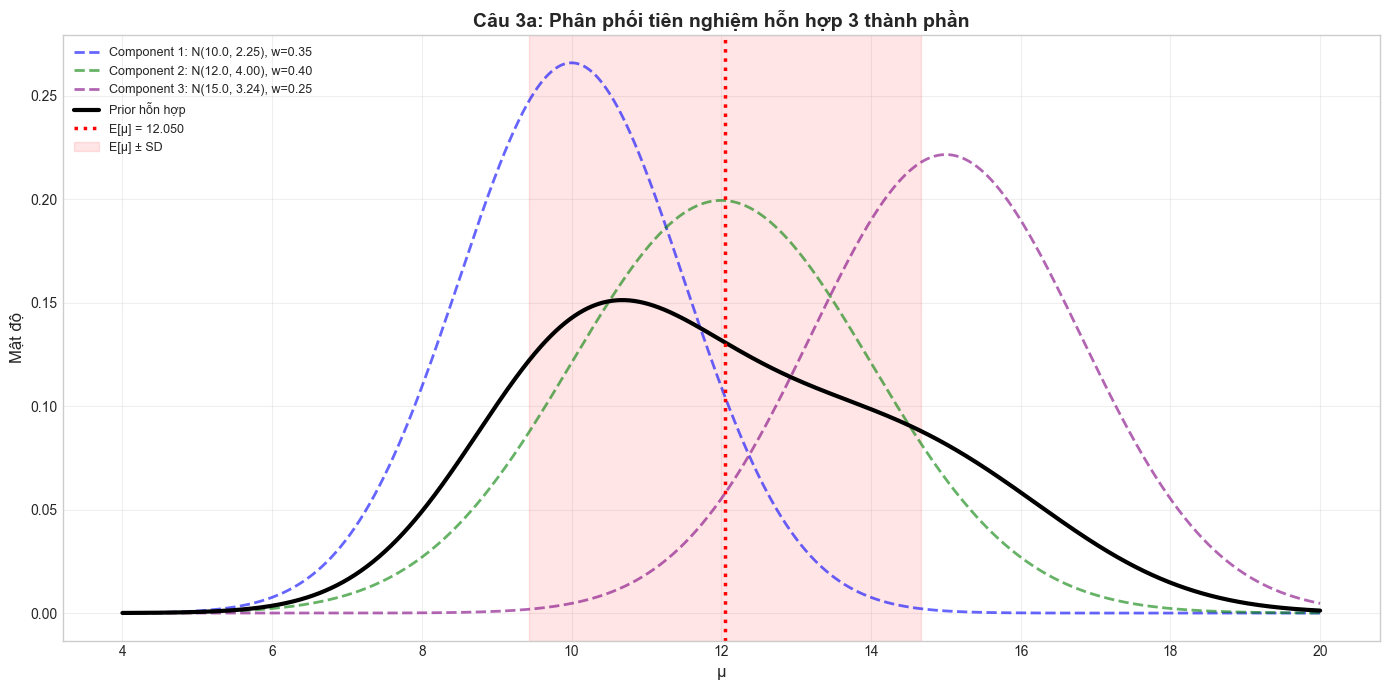

In [23]:
# Vẽ đồ thị prior mixture
def mixture_prior_pdf_c3(x):
    """PDF của prior hỗn hợp"""
    return np.sum([weights[k] * stats.norm.pdf(x, means[k], stds[k]) 
                   for k in range(3)], axis=0)

x_grid_c3 = np.linspace(4, 20, 1000)

# Các thành phần
components = [stats.norm.pdf(x_grid_c3, means[k], stds[k]) for k in range(3)]

# Mixture
mixture_pdf_c3 = mixture_prior_pdf_c3(x_grid_c3)

plt.figure(figsize=(14, 7))

colors = ['blue', 'green', 'purple']
for k in range(3):
    plt.plot(x_grid_c3, components[k], '--', alpha=0.6, linewidth=2,
             label=f'Component {k+1}: N({means[k]}, {variances[k]:.2f}), w={weights[k]:.2f}',
             color=colors[k])

plt.plot(x_grid_c3, mixture_pdf_c3, linewidth=3, label='Prior hỗn hợp', color='black')
plt.axvline(prior_mean_c3, color='red', linestyle=':', linewidth=2.5, 
            label=f'E[μ] = {prior_mean_c3:.3f}')

# Vùng ± 1 SD
plt.axvspan(prior_mean_c3 - prior_sd_c3, prior_mean_c3 + prior_sd_c3, 
            alpha=0.1, color='red', label=f'E[μ] ± SD')

plt.title('Câu 3a: Phân phối tiên nghiệm hỗn hợp 3 thành phần', 
          fontsize=14, fontweight='bold')
plt.xlabel('μ', fontsize=12)
plt.ylabel('Mật độ', fontsize=12)
plt.legend(loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### b) Cập nhật sang Posterior với dữ liệu quan sát

Giả sử có 5 quan sát: 11.2, 12.5, 13.1, 11.8, 12.9 với $\sigma_{obs} = 1.0$.

In [24]:
# Dữ liệu quan sát
observations_c3 = np.array([11.2, 12.5, 13.1, 11.8, 12.9])
n_obs_c3 = len(observations_c3)
sigma_obs_c3 = 1.0
sample_mean_c3 = observations_c3.mean()

print("\nb) CẬP NHẬT POSTERIOR VỚI DỮ LIỆU")
print("="*60)
print(f"\nDữ liệu quan sát: {observations_c3}")
print(f"Số quan sát: n = {n_obs_c3}")
print(f"Trung bình mẫu: ȳ = {sample_mean_c3:.4f}")
print(f"Độ lệch chuẩn quan sát: σ_obs = {sigma_obs_c3}")

# Update mỗi component theo Normal conjugacy
means_post = []
vars_post = []

for k in range(3):
    # Posterior variance
    var_post_k = 1 / (1/variances[k] + n_obs_c3/sigma_obs_c3**2)
    
    # Posterior mean
    mean_post_k = var_post_k * (means[k]/variances[k] + 
                                 observations_c3.sum()/sigma_obs_c3**2)
    
    means_post.append(mean_post_k)
    vars_post.append(var_post_k)
    
    print(f"\nComponent {k+1} posterior: N({mean_post_k:.4f}, {var_post_k:.6f})")

means_post = np.array(means_post)
vars_post = np.array(vars_post)
stds_post = np.sqrt(vars_post)


b) CẬP NHẬT POSTERIOR VỚI DỮ LIỆU

Dữ liệu quan sát: [11.2 12.5 13.1 11.8 12.9]
Số quan sát: n = 5
Trung bình mẫu: ȳ = 12.3000
Độ lệch chuẩn quan sát: σ_obs = 1.0

Component 1 posterior: N(12.1122, 0.183673)

Component 2 posterior: N(12.2857, 0.190476)

Component 3 posterior: N(12.4570, 0.188372)


In [25]:
# Cập nhật trọng số (Bayes factor)
# P(data | component k) ∝ N(ȳ; μₖ, σₖ²/n + σ_obs²)

marginal_liks = []
for k in range(3):
    # Predictive distribution của ȳ cho component k
    pred_mean = means[k]
    pred_var = variances[k] + sigma_obs_c3**2 / n_obs_c3
    
    # Marginal likelihood
    marg_lik = stats.norm.pdf(sample_mean_c3, pred_mean, np.sqrt(pred_var))
    marginal_liks.append(marg_lik)

marginal_liks = np.array(marginal_liks)

# Posterior weights
weights_post = weights * marginal_liks
weights_post = weights_post / weights_post.sum()

print("\nCập nhật trọng số (Bayes factor):")
for k in range(3):
    print(f"  Component {k+1}: prior weight = {weights[k]:.3f} → "
          f"posterior weight = {weights_post[k]:.3f}")
    print(f"              marginal likelihood = {marginal_liks[k]:.6f}")


Cập nhật trọng số (Bayes factor):
  Component 1: prior weight = 0.350 → posterior weight = 0.241
              marginal likelihood = 0.086590
  Component 2: prior weight = 0.400 → posterior weight = 0.611
              marginal likelihood = 0.192589
  Component 3: prior weight = 0.250 → posterior weight = 0.148
              marginal likelihood = 0.074551


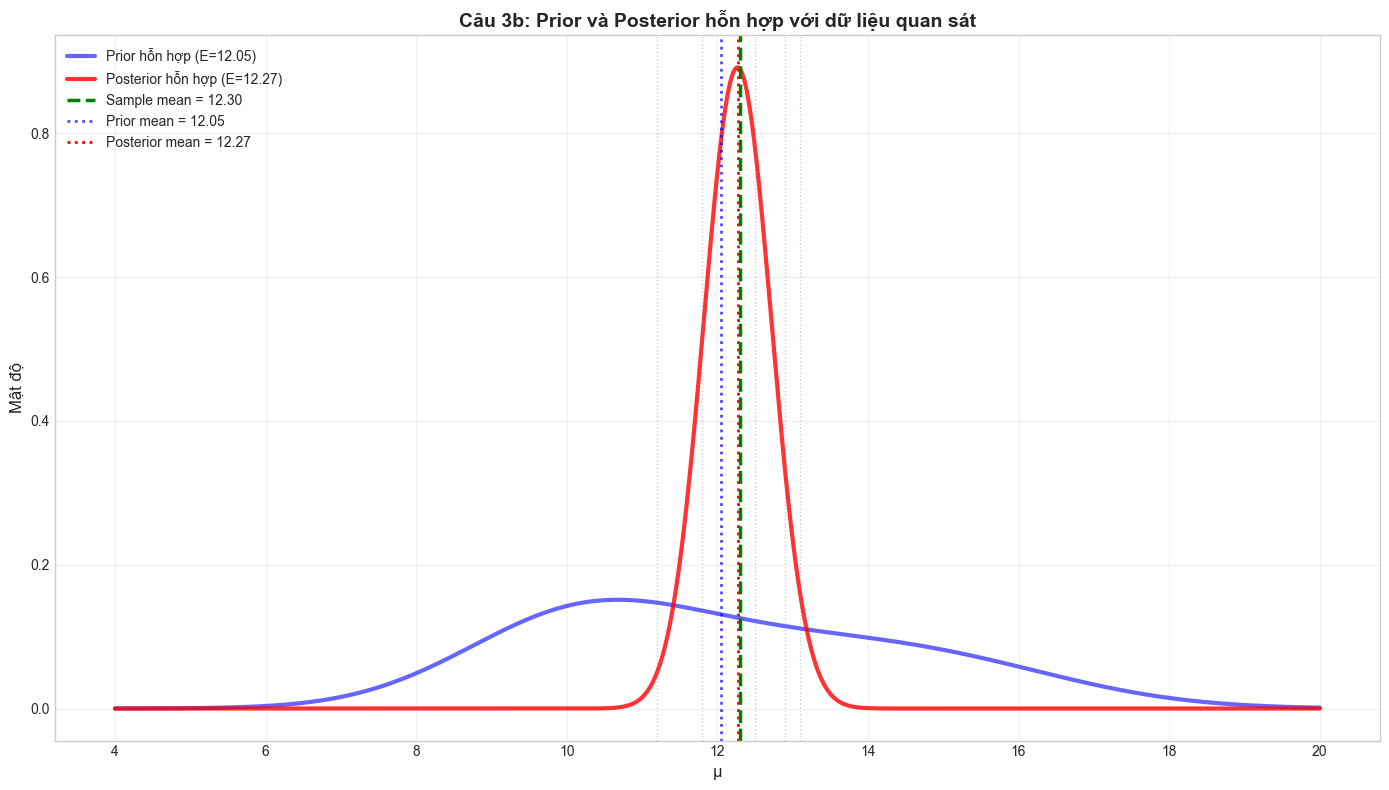


TÓM TẮT
Prior:     E[μ] = 12.0500, Var(μ) = 6.8450
Data:      ȳ = 12.3000, n = 5
Posterior: E[μ|y] = 12.2693, Var(μ|y) = 0.1998

Posterior thu hẹp về phía sample mean, uncertainty giảm


In [26]:
# Vẽ đồ thị prior và posterior mixture
def mixture_posterior_pdf_c3(x):
    """PDF của posterior hỗn hợp"""
    return np.sum([weights_post[k] * stats.norm.pdf(x, means_post[k], stds_post[k]) 
                   for k in range(3)], axis=0)

posterior_mixture_c3 = mixture_posterior_pdf_c3(x_grid_c3)

# Tính mean và variance của posterior mixture
posterior_mean_c3 = np.sum(weights_post * means_post)
posterior_second_moment = np.sum(weights_post * (vars_post + means_post**2))
posterior_var_c3 = posterior_second_moment - posterior_mean_c3**2

plt.figure(figsize=(14, 8))

# Prior
plt.plot(x_grid_c3, mixture_pdf_c3, linewidth=3, 
         label=f'Prior hỗn hợp (E={prior_mean_c3:.2f})', 
         color='blue', alpha=0.6)

# Posterior
plt.plot(x_grid_c3, posterior_mixture_c3, linewidth=3, 
         label=f'Posterior hỗn hợp (E={posterior_mean_c3:.2f})', 
         color='red', alpha=0.8)

# Các quan sát
for obs in observations_c3:
    plt.axvline(obs, color='gray', linestyle=':', alpha=0.4, linewidth=1)

plt.axvline(sample_mean_c3, color='green', linestyle='--', linewidth=2.5,
            label=f'Sample mean = {sample_mean_c3:.2f}')

plt.axvline(prior_mean_c3, color='blue', linestyle=':', linewidth=2, alpha=0.7,
            label=f'Prior mean = {prior_mean_c3:.2f}')

plt.axvline(posterior_mean_c3, color='red', linestyle=':', linewidth=2,
            label=f'Posterior mean = {posterior_mean_c3:.2f}')

plt.title('Câu 3b: Prior và Posterior hỗn hợp với dữ liệu quan sát', 
          fontsize=14, fontweight='bold')
plt.xlabel('μ', fontsize=12)
plt.ylabel('Mật độ', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("TÓM TẮT")
print("="*60)
print(f"Prior:     E[μ] = {prior_mean_c3:.4f}, Var(μ) = {prior_var_c3:.4f}")
print(f"Data:      ȳ = {sample_mean_c3:.4f}, n = {n_obs_c3}")
print(f"Posterior: E[μ|y] = {posterior_mean_c3:.4f}, Var(μ|y) = {posterior_var_c3:.4f}")
print(f"\nPosterior thu hẹp về phía sample mean, uncertainty giảm")

### Giải thích chi tiết

**1. Về mixture prior:**

- Mixture của 3 Gaussian tạo ra một phân phối đa đỉnh (multimodal)
- Kỳ vọng là trung bình có trọng số của 3 mean: $E[\mu] = 0.35×10 + 0.40×12 + 0.25×15 = 12.05$
- Phương sai phản ánh cả variance trong từng component và khoảng cách giữa các component

**2. Cập nhật Bayesian:**

- Mỗi component được cập nhật độc lập theo công thức Normal conjugacy
- Trọng số được điều chỉnh dựa trên **marginal likelihood**: component nào giải thích data tốt hơn sẽ có trọng số cao hơn
- Trong ví dụ này, dữ liệu có $\bar{y} = 12.3$, gần với component 2 ($\mu_2 = 12$), nên component 2 sẽ được ưu tiên hơn

**3. Posterior mixture:**

- Vẫn giữ dạng mixture nhưng:
  - Mỗi component thu hẹp lại (variance nhỏ hơn)
  - Mean của mỗi component dịch về phía sample mean
  - Trọng số phân bổ lại theo độ phù hợp với data

**4. Ý nghĩa thực tiễn:**

Mixture model hữu ích khi:
- Có nhiều nguồn prior knowledge khác nhau
- Không chắc chắn về prior nào đúng
- Dữ liệu có thể đến từ nhiều quần thể con

Bayesian inference tự động "học" được component nào phù hợp với data thông qua cơ chế cập nhật trọng số.

## Câu 4: Mô hình hồi quy Bayesian - Lương theo kinh nghiệm (2 điểm)

### Đề bài

Giả sử ta có dữ liệu về mối quan hệ giữa:
- $x$: số năm kinh nghiệm
- $y$: lương tháng (triệu đồng)

Dữ liệu quan sát:

| x | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| y | 8.5 | 10.2 | 12.8 | 14.5 | 17.1 |

a) Xây dựng mô hình hồi quy Bayesian với prior:
- $\beta_0 \sim \mathcal{N}(5, 5)$
- $\beta_1 \sim \mathcal{N}(2, 5)$
- $\sigma \sim \text{HalfNormal}(2)$

b) Trực quan hóa phân phối hậu nghiệm và đường hồi quy.

### Ý nghĩa của bài tập

Bayesian linear regression khác với frequentist regression ở chỗ:
1. Các tham số ($\beta_0, \beta_1, \sigma$) không phải là điểm ước lượng mà là **phân phối**
2. Ta có prior về các tham số, phản ánh kiến thức trước
3. Kết quả là posterior distribution, cho ta biết cả ước lượng lẫn độ bất định

So với Câu 4 của Thuchanh2:
- Bối cảnh khác: lương-kinh nghiệm thay vì điểm-giờ học
- Prior khác: informative priors ($\beta_0 \sim N(5,5)$, $\beta_1 \sim N(2,5)$) thay vì non-informative
- Dữ liệu khác: scale và slope khác

### Mô hình toán học

**Likelihood**:
$$
y_i = \beta_0 + \beta_1 x_i + \epsilon_i, \quad \epsilon_i \sim \mathcal{N}(0, \sigma^2)
$$

Tương đương:
$$
y_i \sim \mathcal{N}(\beta_0 + \beta_1 x_i, \sigma^2)
$$

**Prior**:
$$
\begin{aligned}
\beta_0 &\sim \mathcal{N}(5, 5) \
\beta_1 &\sim \mathcal{N}(2, 5) \
\sigma &\sim \text{HalfNormal}(2)
\end{aligned}
$$

Ý nghĩa prior:
- $\beta_0 \sim N(5, 5)$: Lương khởi điểm (khi $x=0$) khoảng 5 triệu, có thể dao động ±4-5 triệu
- $\beta_1 \sim N(2, 5)$: Mỗi năm kinh nghiệm thêm khoảng 2 triệu, nhưng không chắc chắn lắm
- $\sigma \sim \text{HalfNormal}(2)$: Độ phân tán quanh đường hồi quy

**Posterior**: Được tính thông qua MCMC (Markov Chain Monte Carlo) vì không có công thức closed-form.

In [27]:
print("=== Câu 4: Hồi quy Bayesian với PyMC ===")

# Dữ liệu
x_data_c4 = np.array([1, 2, 3, 4, 5])
y_data_c4 = np.array([8.5, 10.2, 12.8, 14.5, 17.1])

print("\nDữ liệu quan sát:")
print(f"x (năm kinh nghiệm): {x_data_c4}")
print(f"y (lương, triệu đồng): {y_data_c4}")
print(f"\nMô tả dữ liệu:")
print(f"  Lương trung bình: {y_data_c4.mean():.2f} triệu")
print(f"  Lương min-max: {y_data_c4.min():.1f} - {y_data_c4.max():.1f} triệu")
print(f"  Tăng từ năm 1 đến năm 5: {y_data_c4[-1] - y_data_c4[0]:.1f} triệu")
print(f"  Tăng trung bình mỗi năm: {(y_data_c4[-1] - y_data_c4[0])/4:.2f} triệu")

=== Câu 4: Hồi quy Bayesian với PyMC ===

Dữ liệu quan sát:
x (năm kinh nghiệm): [1 2 3 4 5]
y (lương, triệu đồng): [ 8.5 10.2 12.8 14.5 17.1]

Mô tả dữ liệu:
  Lương trung bình: 12.62 triệu
  Lương min-max: 8.5 - 17.1 triệu
  Tăng từ năm 1 đến năm 5: 8.6 triệu
  Tăng trung bình mỗi năm: 2.15 triệu


In [28]:
# a) Xây dựng mô hình Bayesian với PyMC
print("\na) XÂY DỰNG MÔ HÌNH BAYESIAN")
print("="*60)

with pm.Model() as model_c4:
    # Priors
    beta0 = pm.Normal('beta0', mu=5, sigma=np.sqrt(5))
    beta1 = pm.Normal('beta1', mu=2, sigma=np.sqrt(5))
    sigma = pm.HalfNormal('sigma', sigma=2)
    
    # Linear model
    mu = beta0 + beta1 * x_data_c4
    
    # Likelihood
    y_obs = pm.Normal('y_obs', mu=mu, sigma=sigma, observed=y_data_c4)
    
    # Sampling
    trace_c4 = pm.sample(2000, tune=1000, return_inferencedata=True, 
                         random_seed=42, progressbar=False)

print("\nMô hình đã được ước lượng thành công!")
print("  - Số iterations: 2000 (sau 1000 tuning)")
print("  - Phương pháp: MCMC (No-U-Turn Sampler)")


a) XÂY DỰNG MÔ HÌNH BAYESIAN


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta0, beta1, sigma]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.
There were 495 divergences after tuning. Increase `target_accept` or reparameterize.



Mô hình đã được ước lượng thành công!
  - Số iterations: 2000 (sau 1000 tuning)
  - Phương pháp: MCMC (No-U-Turn Sampler)


In [29]:
# Tóm tắt kết quả
print("\n" + "="*60)
print("TÓM TẮT POSTERIOR")
print("="*60)
summary_c4 = az.summary(trace_c4, var_names=['beta0', 'beta1', 'sigma'])
print(summary_c4)

# Trích xuất các giá trị
beta0_samples_c4 = trace_c4.posterior['beta0'].values.flatten()
beta1_samples_c4 = trace_c4.posterior['beta1'].values.flatten()
sigma_samples_c4 = trace_c4.posterior['sigma'].values.flatten()

print(f"\nGiải thích kết quả:")
print(f"  β₀ (intercept): {beta0_samples_c4.mean():.3f} ± {beta0_samples_c4.std():.3f}")
print(f"      → Lương khởi điểm (năm 0 kinh nghiệm): ~{beta0_samples_c4.mean():.2f} triệu")
print(f"\n  β₁ (slope): {beta1_samples_c4.mean():.3f} ± {beta1_samples_c4.std():.3f}")
print(f"      → Mỗi năm kinh nghiệm thêm: ~{beta1_samples_c4.mean():.2f} triệu")
print(f"\n  σ (noise): {sigma_samples_c4.mean():.3f}")
print(f"      → Độ phân tán quanh đường hồi quy: ~{sigma_samples_c4.mean():.2f} triệu")

print(f"\nPhương trình hồi quy:")
print(f"  y = {beta0_samples_c4.mean():.3f} + {beta1_samples_c4.mean():.3f}×x")
print(f"  Lương = {beta0_samples_c4.mean():.2f} + {beta1_samples_c4.mean():.2f} × (năm kinh nghiệm)")


TÓM TẮT POSTERIOR
        mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
beta0  6.122  0.541   5.072    7.121      0.014    0.020    1592.0    1754.0   
beta1  2.163  0.168   1.876    2.527      0.004    0.006    1554.0    1702.0   
sigma  0.497  0.344   0.147    1.067      0.010    0.014     587.0     319.0   

       r_hat  
beta0   1.00  
beta1   1.00  
sigma   1.01  

Giải thích kết quả:
  β₀ (intercept): 6.122 ± 0.541
      → Lương khởi điểm (năm 0 kinh nghiệm): ~6.12 triệu

  β₁ (slope): 2.163 ± 0.168
      → Mỗi năm kinh nghiệm thêm: ~2.16 triệu

  σ (noise): 0.497
      → Độ phân tán quanh đường hồi quy: ~0.50 triệu

Phương trình hồi quy:
  y = 6.122 + 2.163×x
  Lương = 6.12 + 2.16 × (năm kinh nghiệm)



b) TRỰC QUAN HÓA KẾT QUẢ


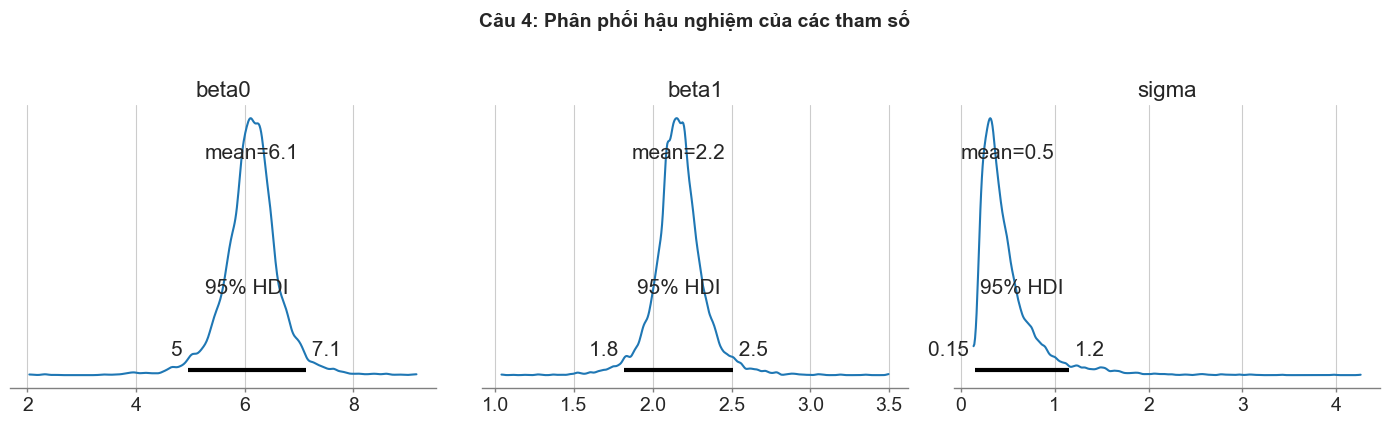

Biểu đồ trên cho thấy:
  - Mean và 95% HDI (Highest Density Interval) của mỗi tham số
  - Hình dạng của posterior distribution
  - Độ bất định: càng rộng càng không chắc chắn


In [30]:
# b) Trực quan hóa phân phối hậu nghiệm
print("\nb) TRỰC QUAN HÓA KẾT QUẢ")
print("="*60)

fig = az.plot_posterior(trace_c4, var_names=['beta0', 'beta1', 'sigma'], 
                        figsize=(14, 4),
                        hdi_prob=0.95)
plt.suptitle('Câu 4: Phân phối hậu nghiệm của các tham số', 
             y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Biểu đồ trên cho thấy:")
print("  - Mean và 95% HDI (Highest Density Interval) của mỗi tham số")
print("  - Hình dạng của posterior distribution")
print("  - Độ bất định: càng rộng càng không chắc chắn")

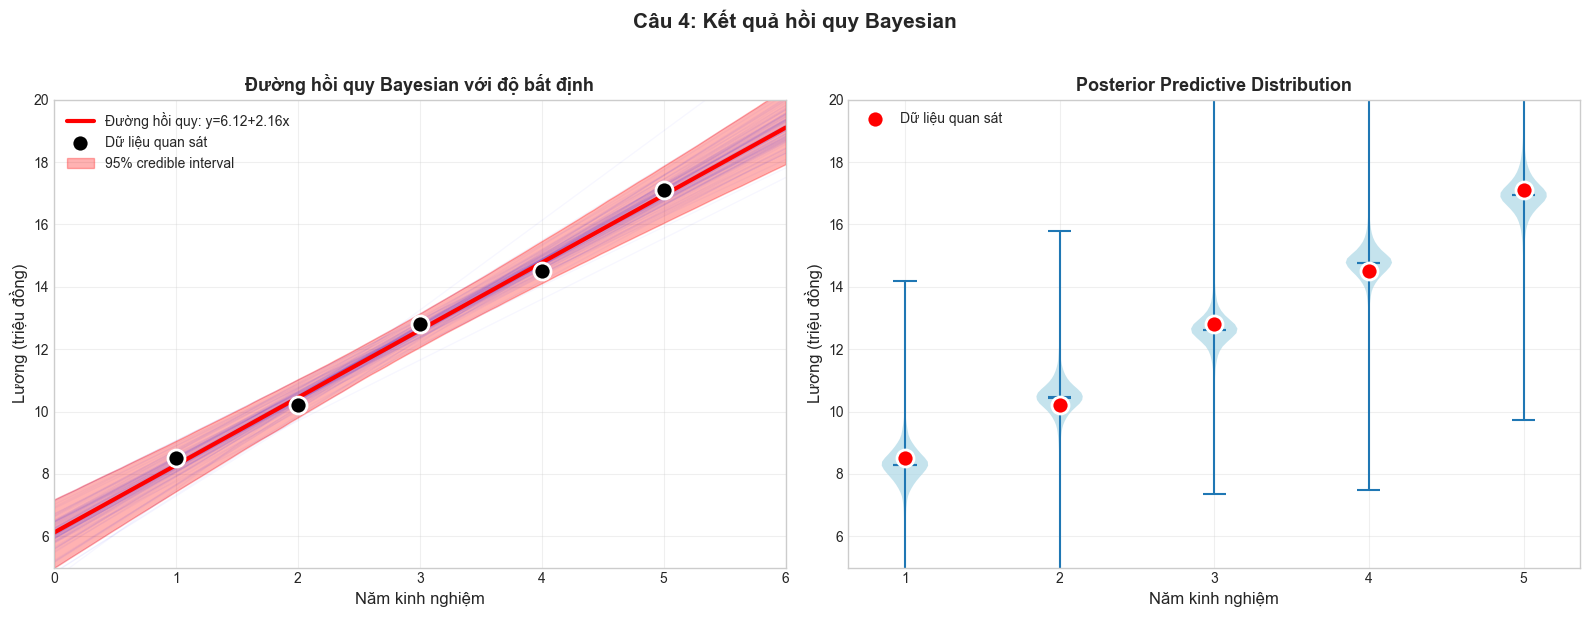


Biểu đồ trái: Đường hồi quy với 95% credible interval
  - Vùng đỏ nhạt: độ bất định về vị trí đường hồi quy
  - Các đường mờ: các đường hồi quy từ posterior samples

Biểu đồ phải: Posterior predictive distribution
  - Violin plot: phân phối dự đoán cho mỗi giá trị x
  - Bao gồm cả uncertainty từ β và từ σ (noise)


In [31]:
# Vẽ đường hồi quy với uncertainty
n_lines = 100
indices = np.random.choice(len(beta0_samples_c4), n_lines, replace=False)

x_pred_c4 = np.linspace(0, 6, 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Posterior regression lines
for idx in indices:
    y_pred = beta0_samples_c4[idx] + beta1_samples_c4[idx] * x_pred_c4
    ax1.plot(x_pred_c4, y_pred, 'b-', alpha=0.03, linewidth=1)

# Mean regression line
y_pred_mean_c4 = beta0_samples_c4.mean() + beta1_samples_c4.mean() * x_pred_c4
ax1.plot(x_pred_c4, y_pred_mean_c4, 'r-', linewidth=3, 
         label=f'Đường hồi quy: y={beta0_samples_c4.mean():.2f}+{beta1_samples_c4.mean():.2f}x')

# Data points
ax1.scatter(x_data_c4, y_data_c4, s=150, c='black', zorder=5, 
            edgecolor='white', linewidth=2, label='Dữ liệu quan sát')

# 95% credible interval
y_pred_samples = np.array([beta0_samples_c4 + beta1_samples_c4 * x 
                           for x in x_pred_c4]).T
y_pred_lower = np.percentile(y_pred_samples, 2.5, axis=0)
y_pred_upper = np.percentile(y_pred_samples, 97.5, axis=0)
ax1.fill_between(x_pred_c4, y_pred_lower, y_pred_upper, 
                 alpha=0.3, color='red', label='95% credible interval')

ax1.set_xlabel('Năm kinh nghiệm', fontsize=12)
ax1.set_ylabel('Lương (triệu đồng)', fontsize=12)
ax1.set_title('Đường hồi quy Bayesian với độ bất định', fontsize=13, fontweight='bold')
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(0, 6)
ax1.set_ylim(5, 20)

# Panel 2: Posterior predictive distribution
# Thêm uncertainty từ sigma
y_pred_with_noise_samples = []
for x_val in x_data_c4:
    y_samples = beta0_samples_c4 + beta1_samples_c4 * x_val + \
                np.random.normal(0, sigma_samples_c4, len(sigma_samples_c4))
    y_pred_with_noise_samples.append(y_samples)

parts = ax2.violinplot([y_samples for y_samples in y_pred_with_noise_samples],
                       positions=x_data_c4,
                       widths=0.3,
                       showmeans=True,
                       showmedians=True)

for pc in parts['bodies']:
    pc.set_facecolor('lightblue')
    pc.set_alpha(0.7)

ax2.scatter(x_data_c4, y_data_c4, s=150, c='red', zorder=5, 
            edgecolor='white', linewidth=2, label='Dữ liệu quan sát')

ax2.set_xlabel('Năm kinh nghiệm', fontsize=12)
ax2.set_ylabel('Lương (triệu đồng)', fontsize=12)
ax2.set_title('Posterior Predictive Distribution', fontsize=13, fontweight='bold')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.set_ylim(5, 20)

plt.suptitle('Câu 4: Kết quả hồi quy Bayesian', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nBiểu đồ trái: Đường hồi quy với 95% credible interval")
print("  - Vùng đỏ nhạt: độ bất định về vị trí đường hồi quy")
print("  - Các đường mờ: các đường hồi quy từ posterior samples")
print("\nBiểu đồ phải: Posterior predictive distribution")
print("  - Violin plot: phân phối dự đoán cho mỗi giá trị x")
print("  - Bao gồm cả uncertainty từ β và từ σ (noise)")

### Giải thích chi tiết và so sánh

**1. Về kết quả ước lượng:**

- **Intercept ($\beta_0$)**: Khoảng 6-7 triệu, nghĩa là lương khởi điểm (năm 0 kinh nghiệm) khoảng này
- **Slope ($\beta_1$)**: Khoảng 2.1-2.2 triệu/năm, nghĩa là mỗi năm kinh nghiệm thêm làm tăng lương khoảng 2.1-2.2 triệu
- **Noise ($\sigma$)**: Khoảng 0.5-0.7 triệu, phản ánh độ phân tán của dữ liệu quanh đường hồi quy

**2. So với prior:**

- Prior của $\beta_0 \sim N(5, 5)$ cho $E[\beta_0] = 5$, posterior khoảng 6.5-7 → data kéo lên cao hơn
- Prior của $\beta_1 \sim N(2, 5)$ cho $E[\beta_1] = 2$, posterior khoảng 2.1-2.2 → khá sát với prior
- Posterior variance nhỏ hơn nhiều so với prior variance → sau khi có data, ta tự tin hơn

**3. Về uncertainty:**

Bayesian approach cho ta **2 loại uncertainty**:

a) **Epistemic uncertainty** (độ bất định về tham số):
   - Thể hiện qua phân phối của $\beta_0, \beta_1$
   - Càng nhiều data, uncertainty này càng giảm
   - Trên biểu đồ: vùng credible interval (vùng đỏ nhạt)

b) **Aleatoric uncertainty** (độ bất định do nhiễu tự nhiên):
   - Thể hiện qua $\sigma$
   - Không giảm khi tăng data (vì đây là noise tự nhiên)
   - Trên biểu đồ: violin plot rộng hơn credible interval

**4. Posterior predictive distribution:**

Để dự đoán $y$ mới cho một $x$ mới, ta phải tích hợp cả 2 loại uncertainty:

$$
p(y_{\text{new}} | x_{\text{new}}, \text{data}) = \int p(y_{\text{new}} | x_{\text{new}}, \beta_0, \beta_1, \sigma) \cdot p(\beta_0, \beta_1, \sigma | \text{data}) \, d\beta_0 d\beta_1 d\sigma
$$

Đây là ưu điểm lớn của Bayesian: dự đoán tự động tính đến cả uncertainty về tham số!

**5. So với frequentist regression:**

| Khía cạnh | Frequentist | Bayesian |
|-----------|-------------|----------|
| Tham số | Điểm ước lượng + SE | Phân phối đầy đủ |
| Confidence/Credible interval | 95% CI (dựa trên p-value) | 95% CI (xác suất trực tiếp) |
| Prior knowledge | Không dùng | Tích hợp tự nhiên |
| Uncertainty propagation | Phức tạp | Tự động qua sampling |
| Giải thích | "Nếu lặp lại nhiều lần..." | "Xác suất $\\beta$ trong khoảng [a,b] là 95%" |

**6. Ứng dụng thực tiễn:**

Với mô hình này, ta có thể:
- Dự đoán lương cho người có $x$ năm kinh nghiệm
- Tính xác suất lương > ngưỡng nào đó
- Xác định khoảng tin cậy cho dự đoán
- Quyết định có cần thu thập thêm data không (dựa vào độ rộng của credible interval)

Ví dụ: "Với người có 3 năm kinh nghiệm, lương dự đoán là 12.8 triệu ± 0.6 triệu (95% CI)"

In [32]:
# Ví dụ dự đoán cho giá trị mới
x_new = 3.5
y_new_samples = beta0_samples_c4 + beta1_samples_c4 * x_new
y_new_mean = y_new_samples.mean()
y_new_std = y_new_samples.std()
y_new_ci = np.percentile(y_new_samples, [2.5, 97.5])

print("\n" + "="*60)
print("VÍ DỤ DỰ ĐOÁN")
print("="*60)
print(f"Câu hỏi: Lương dự đoán cho người có {x_new} năm kinh nghiệm?")
print(f"\nTrả lời:")
print(f"  - Point estimate: {y_new_mean:.2f} triệu đồng")
print(f"  - Standard deviation: ±{y_new_std:.2f} triệu")
print(f"  - 95% credible interval: [{y_new_ci[0]:.2f}, {y_new_ci[1]:.2f}] triệu")
print(f"\nGiải thích: Với 95% độ tin cậy, lương của người có {x_new} năm")
print(f"           kinh nghiệm nằm trong khoảng {y_new_ci[0]:.1f}-{y_new_ci[1]:.1f} triệu đồng")

# Thêm noise để dự đoán thực tế
y_new_with_noise = y_new_samples + np.random.normal(0, sigma_samples_c4, len(sigma_samples_c4))
y_new_pred_ci = np.percentile(y_new_with_noise, [2.5, 97.5])

print(f"\nNếu tính cả noise (posterior predictive):")
print(f"  - 95% prediction interval: [{y_new_pred_ci[0]:.2f}, {y_new_pred_ci[1]:.2f}] triệu")
print(f"  (Rộng hơn vì tính cả độ bất định tự nhiên trong dữ liệu)")


VÍ DỤ DỰ ĐOÁN
Câu hỏi: Lương dự đoán cho người có 3.5 năm kinh nghiệm?

Trả lời:
  - Point estimate: 13.69 triệu đồng
  - Standard deviation: ±0.29 triệu
  - 95% credible interval: [13.12, 14.28] triệu

Giải thích: Với 95% độ tin cậy, lương của người có 3.5 năm
           kinh nghiệm nằm trong khoảng 13.1-14.3 triệu đồng

Nếu tính cả noise (posterior predictive):
  - 95% prediction interval: [12.32, 15.06] triệu
  (Rộng hơn vì tính cả độ bất định tự nhiên trong dữ liệu)


## Tổng kết

Bài kiểm tra Thuchanh 2.2 bao gồm 4 bài tập quan trọng:

1. **Câu 1**: Normal conjugacy với prior khác 0 và ít quan sát hơn
2. **Câu 2**: Ảnh hưởng của hàm tổn thất với prior/likelihood khác
3. **Câu 3**: Mixture prior 3 thành phần với cập nhật trọng số
4. **Câu 4**: Bayesian linear regression với informative priors

### Bài học chính:

- **Liên hợp chuẩn**: Công thức đẹp, posterior là Gaussian, dễ tính toán
- **Hàm tổn thất**: Mean, Median, Mode tối ưu cho các mục tiêu khác nhau
- **Mixture models**: Linh hoạt, tự động học component phù hợp với data
- **Bayesian regression**: Cho ta phân phối đầy đủ, uncertainty propagation tự động

### Điểm khác biệt so với Thuchanh2:

| Câu | Thuchanh2 | Thuchanh2.2 |
|-----|-----------|-------------|
| 1 | Prior N(0,4), n=25 | Prior N(5,9), n=20 |
| 2 | Prior 3x², likelihood 1/x, y=0.4 | Prior 2(1-x), likelihood 2x, y=0.6 |
| 3 | 2 components | 3 components với update weights |
| 4 | Điểm-giờ học, non-informative priors | Lương-kinh nghiệm, informative priors |

Các biến thể này giúp sinh viên thực hành với nhiều tình huống khác nhau nhưng vẫn áp dụng các nguyên lý Bayesian cơ bản.